# Utilização do dataset breast cancer

In [1]:
import pandas as pd
#Importando bibliotecas para visualização de dados
import matplotlib.pyplot as plt
import seaborn as sb

In [2]:
from pathlib import Path

# Procura o CSV na pasta atual e nas pastas acima dela.
pasta_atual = Path.cwd().resolve()
for pasta in (pasta_atual, *pasta_atual.parents):
    caminho_dataset = pasta / 'dataset-breast-cancer' / 'data.csv'
    if caminho_dataset.is_file():
        break
else:
    raise FileNotFoundError(
        'dataset-breast-cancer/data.csv não encontrado. '
        'Abra o notebook em uma pasta do projeto.'
    )

dados = pd.read_csv(caminho_dataset)
dados.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


### Remoção de colunas sem impacto (id e Unnamed: 32)

In [3]:
dados.drop(columns=["id", "Unnamed: 32"], errors="ignore", inplace=True)

### Verificação dos dados: </br> 
- Nome da colunas e totalização
- Colunas que possuem dados nulos
- Tipo do dado

In [4]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    str    
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  569 non-null

### Verificação de quais valores há no campo diagnosis, que é o único do tipo string

In [5]:
set(dados.diagnosis)

{'B', 'M'}

#### Somente o dado "diagnosis" é do tipo texto, então transformarei para inteiro.
- <strong> B </strong> será igual a 0
- <strong> M </strong> será igual a 1 

In [6]:
dados['diagnosis'] = dados['diagnosis'].map({'M': 1, 'B': 0})
dados.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Quantos são do diagnóstico Maligno (1) e do Benigno (0)?

In [7]:
dados['diagnosis'].value_counts()

diagnosis
0    357
1    212
Name: count, dtype: int64

### Proporcionalmente temos mais registros de câncer benigno do que maligno

In [8]:
dados["diagnosis"].value_counts(normalize=True).mul(100).round(2)

diagnosis
0    62.74
1    37.26
Name: proportion, dtype: float64

## Confirmação que não há valores nulos

In [9]:
dados.isnull().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

## Verificação se há dados duplicados

In [10]:
dados.duplicated().sum()

np.int64(0)

## Matriz de correlação entre os dados

<Axes: >

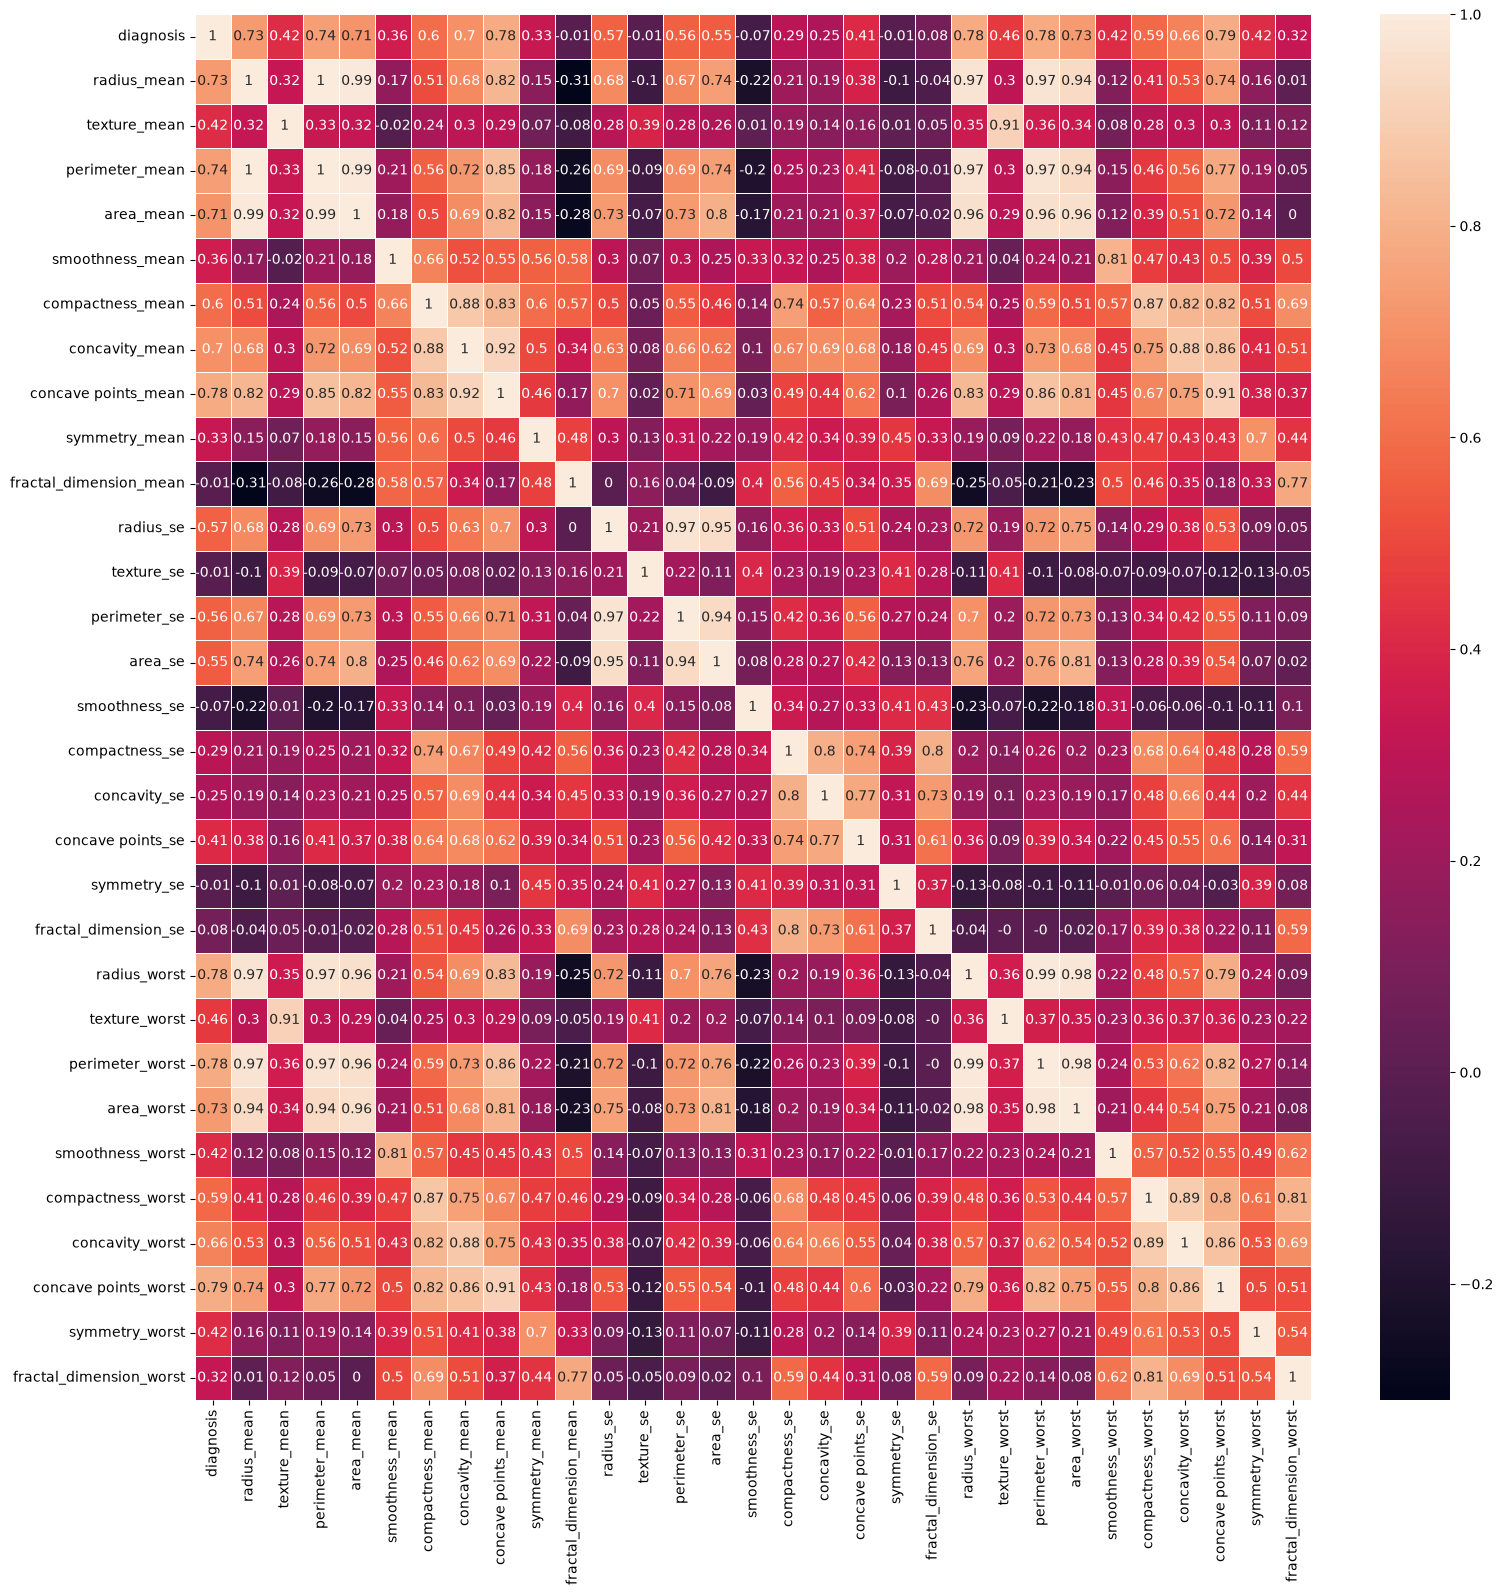

In [11]:
correlation_matriz = dados.corr().round(2)
fig, ax = plt.subplots(figsize=(18,18))
sb.heatmap(correlation_matriz,annot=True, linewidths=0.5, ax=ax)

### Com a matriz de correlação acima podemos ver que as mais correlacionadas com a variável alvo (diagnosis) são:
* radius_mean 0.73
* perimeter_mean 0.74
* concave points_mean 0.78

* radius_worst 0.78
* perimeter_worst 0.78
* concave points_worst 0.79


## Usando as 30 features preditivas e a variável-alvo (diagnosis)

In [12]:
Y = dados["diagnosis"]
X = dados.drop(columns="diagnosis")

print("Preditivas:", X.shape)
print("Alvo:", Y.shape)

Preditivas: (569, 30)
Alvo: (569,)


## Separação dados para treino e teste
- Separei 20% dos casos para teste e 80% para o treinamento.
- Utilizando random_state em 42, para garantir sempre a mesma quantidade na divisão dos dados. Sempre que o código é re-executado os mesmo registros são selecionados para treino e teste. 
- O stratify preservará a proporção de casos benignos e malignos.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42, stratify=Y)

print("Treino preditivas:", X_train.shape)
print("Teste preditivas:", X_test.shape)

Treino preditivas: (455, 30)
Teste preditivas: (114, 30)


## Distribuição do dataset

Através da aplicação do boxplot, podemos ver que as variáveis apresentam amplitudes distintas. Por exemplo, os valores da área apresentam valores muito maiores que as demais features

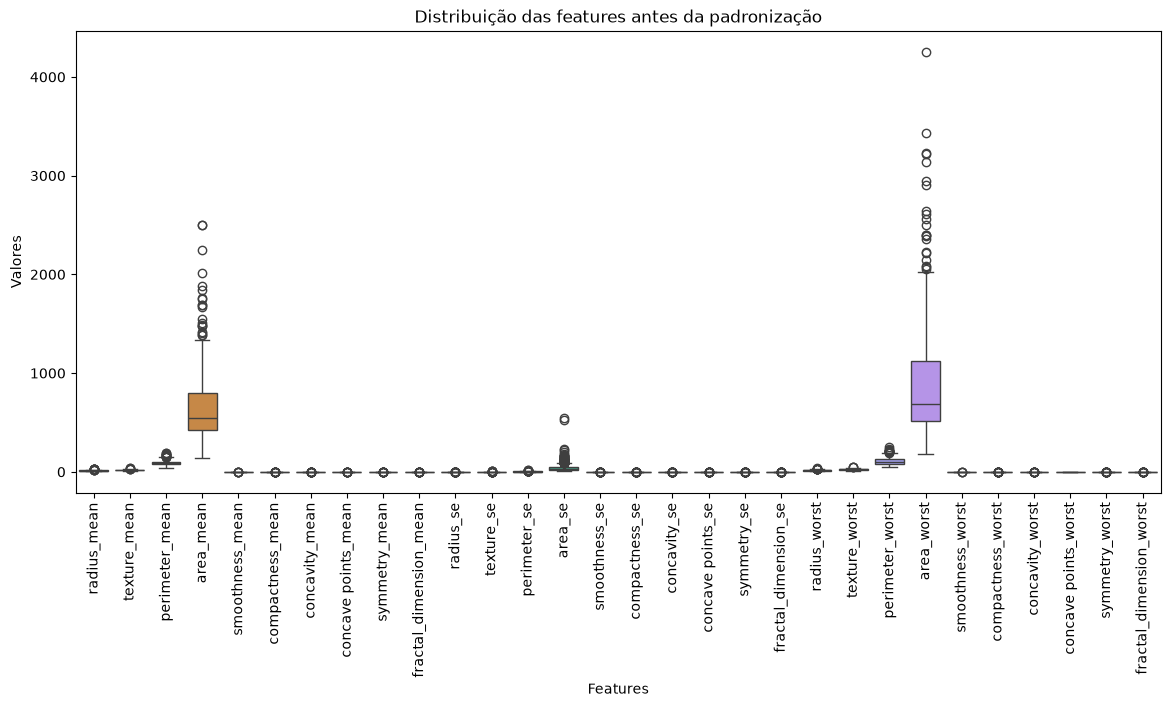

In [14]:
import matplotlib.pyplot as plt
import seaborn as sb

plt.figure(figsize=(14, 6))

sb.boxplot(data=X_train)

plt.title("Distribuição das features antes da padronização")
plt.xlabel("Features")
plt.ylabel("Valores")
plt.xticks(rotation=90)

plt.show()

## StandardScaler
- Reduzirá a discrepância entre as escalas das diferentes features.

### Abaixo é feita importação da lib para ajustar a escala padrão no conjunto de treinamento para o cálculo da média e do desvio padrão de cada variável.

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [16]:
# Padronização usando somente os dados de treino
X_train_scaled = scaler.transform(X_train)

# Padronização usando os dados de teste
X_test_scaled = scaler.transform(X_test)

### Distribuição do dataset padronizado
Após aplicar o standardScaler, as variáveis foram padronizadas com base na média e o desvio padrão do conjunto de treinamento.

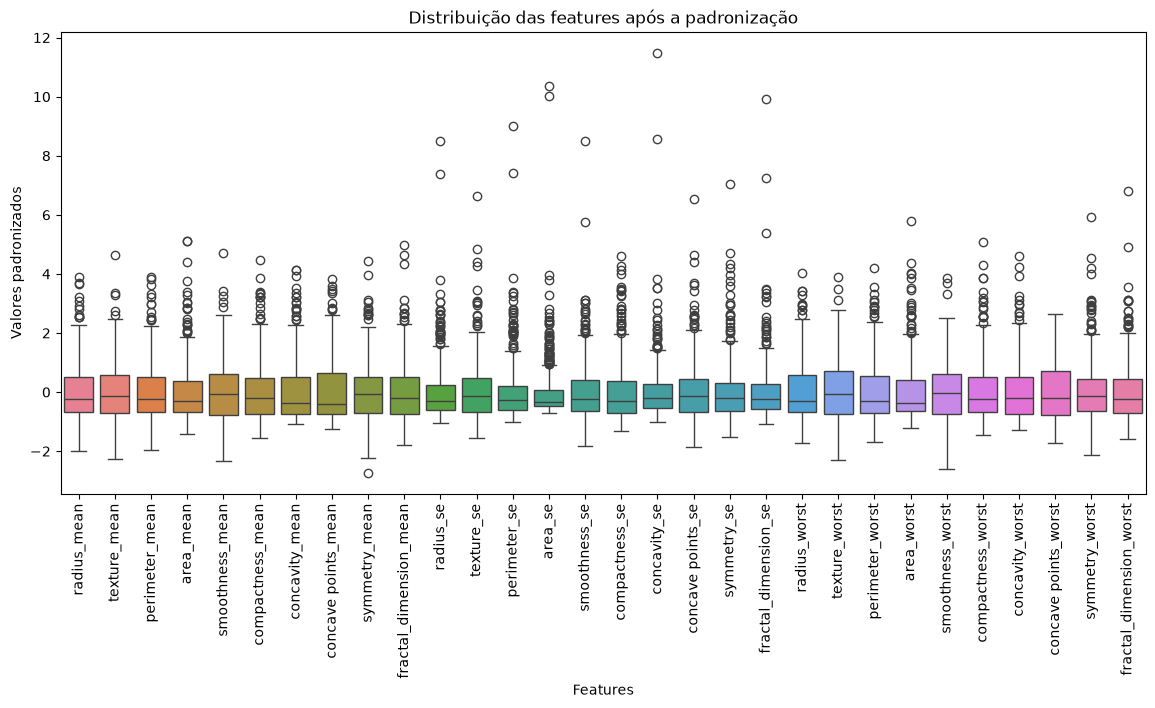

In [17]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)

plt.figure(figsize=(14, 6))

sb.boxplot(data=X_train_scaled_df)

plt.title("Distribuição das features após a padronização")
plt.xlabel("Features")
plt.ylabel("Valores padronizados")
plt.xticks(rotation=90)

plt.show()

# Regressão Logística

In [18]:
from sklearn.linear_model import LogisticRegression

modelo_logistico = LogisticRegression()

modelo_logistico.fit(X_train_scaled, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

### Realizando a predição de todo o conjunto de teste

In [19]:
Y_pred = modelo_logistico.predict(X_test_scaled)
print("Diagnóstico verdadeiro:", Y_test.values)
print("Predições:", Y_pred)

Diagnóstico verdadeiro: [0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 1 1]
Predições: [0 1 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 0 1]


### Podemos verificar que há valores do teste e da predição que estão conflitando

In [20]:
print("Teste", Y_test.values[4])
print("Predição", Y_pred[4])

Teste 0
Predição 1


### Verificação da Matriz de confusão, Recall, Acurácia e Precisão 

#### <h5>Matriz de Confusão:</h5>

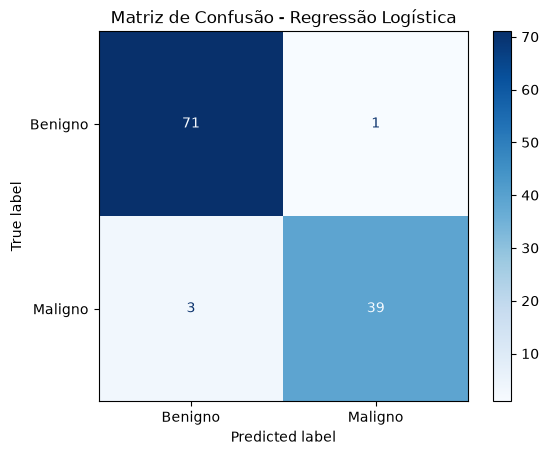

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matriz_confusao = confusion_matrix(Y_test, Y_pred)

ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Benigno", "Maligno"] ).plot(cmap="Blues")
plt.title("Matriz de Confusão - Regressão Logística")
plt.show()

Tivemos:
* 71 casos benignos previstos corretamente (TN-True Negative)
* 1 caso benigno previsto como maligno 🚨​ (FP - False Positive)
* 3 casos onde era **maligno**, mas foi previsto como benigno (FN - False Negative) 🚨​🚨​
* 39 eram malignos e foram classificados corretamente como malignos (TP - True Positive)

#### <h5>Recall: Dos casos malignos, quantos foram detectados corretamente?</h5> 

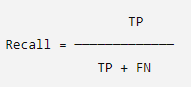

In [22]:
#Calculando o recall manualmente
x_recall = 39/(39+3)
print("Recall Manual:", f"{x_recall*100:.2f} %")

Recall Manual: 92.86 %


In [23]:
from sklearn.metrics import recall_score

recall = recall_score(Y_test, Y_pred)

print("Recall:", f"{recall*100:.2f} %")

Recall: 92.86 %


### Precisão: Dos que foram previsto como malignos, quantos de fato eram?

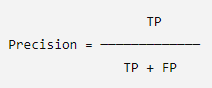

In [24]:
m_precision = 39/(39+1)
print("Precision Manual:", f"{m_precision*100:.2f} %")

Precision Manual: 97.50 %


In [25]:
from sklearn.metrics import precision_score

precision = precision_score(Y_test, Y_pred)

print("Precision:", f"{precision*100:.2f} %")

Precision: 97.50 %


RECALL
"Quantos cânceres eu consegui encontrar?"

PRECISION
"Quando digo que é câncer, quantas vezes estou certo?"

### F1-score: É o equilíbrio entre o Precision e Recall

In [26]:
from sklearn.metrics import f1_score

f1 = f1_score(Y_test, Y_pred)

print("F1-score:", f"{f1*100:.2f} %")

F1-score: 95.12 %


### Acurácia: Quantos o modelo classificou corretamente?

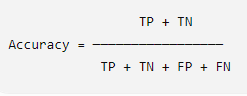

In [27]:
m_acuracy = (39+71)/(39+71+1+3)
print("Accuracy Manual:", f"{m_acuracy*100:.2f} %")

Accuracy Manual: 96.49 %


In [28]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(Y_test, Y_pred)
print("Accuracy:", f"{accuracy*100:.2f} %")

Accuracy: 96.49 %


In [29]:
#Conclusão
print("Matriz de confusão: ", matriz_confusao)
print("Recall:", f"{recall*100:.2f} %")
print("Precision:", f"{precision*100:.2f} %")
print("F1-score:", f"{f1*100:.2f} %")
print("Accuracy:", f"{accuracy*100:.2f} %")

Matriz de confusão:  [[71  1]
 [ 3 39]]
Recall: 92.86 %
Precision: 97.50 %
F1-score: 95.12 %
Accuracy: 96.49 %


# Coeficientes

Para analisar a influência das features nas previsões realizadas, serão analisados os coeficientes aprendidos pelo modelo. Como as variáveis já foram padronizadas utilizando o StandardScaler, os coeficientes podem ser comparados considerando magnitude e direção.

In [30]:
print("Quantidade de features:", len(X.columns))
print("Quantidade de coeficientes:", len(modelo_logistico.coef_[0]))

coeficientes = pd.DataFrame({
    "Feature": X.columns,
    "Coeficiente": modelo_logistico.coef_[0]
})

coeficientes

Quantidade de features: 30
Quantidade de coeficientes: 30


,Feature,Coeficiente
0,radius_mean,0.361150
1,texture_mean,0.482219
2,perimeter_mean,0.353160
3,area_mean,0.439950
4,smoothness_mean,0.350622
5,compactness_mean,-0.439546
6,concavity_mean,0.782298
7,concave points_mean,0.952813
8,symmetry_mean,-0.163991
9,fractal_dimension_mean,-0.080865


In [31]:
coeficientes["Magnitude"] = coeficientes["Coeficiente"].abs()
coeficientes = coeficientes.sort_values(by="Magnitude", ascending=False)
display(coeficientes)

,Feature,Coeficiente,Magnitude
21,texture_worst,1.434093,1.434093
10,radius_se,1.233325,1.233325
28,symmetry_worst,1.061264,1.061264
7,concave points_mean,0.952813,0.952813
26,concavity_worst,0.911406,0.911406
13,area_se,0.909029,0.909029
15,compactness_se,-0.906925,0.906925
23,area_worst,0.900477,0.900477
20,radius_worst,0.896968,0.896968
6,concavity_mean,0.782298,0.782298


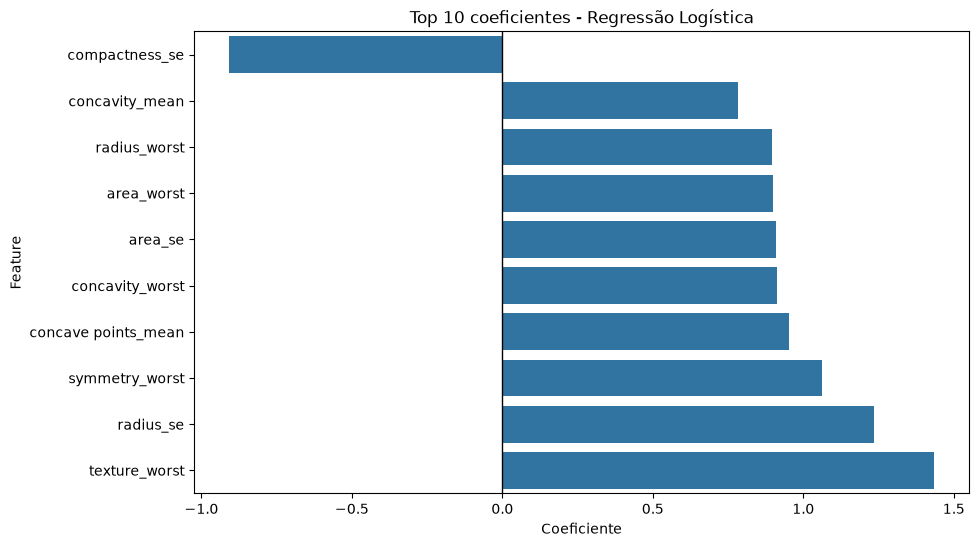

In [32]:
top_coeficientes = coeficientes.head(10).sort_values(by="Coeficiente")

plt.figure(figsize=(10, 6))

sb.barplot(data=top_coeficientes, x="Coeficiente", y="Feature")

plt.axvline(0, color="black", linewidth=1)

plt.title("Top 10 coeficientes - Regressão Logística")
plt.xlabel("Coeficiente")
plt.ylabel("Feature")
plt.show()

# Conclusão - Regressão Logística

A análise dos coeficientes da regressão logística mostrou que **texture_worst**, **radius_se** e **symmetry_worst** apresentaram as maiores magnitudes positivas entre as variáveis do modelo. A classe 1 representa os casos malignos, logo, os coeficientes positivos indicam que valores maiores dessas features aumentam a tendência do modelo de classificar o caso como maligno.

Algumas features apresentaram coeficientes negativos, como **compactness_se**. Nesse caso, o aumento da característica atua no sentido contrário à classe maligna, considerando as demais variáveis utilizadas pelo modelo.

Os coeficientes não devem ser interpretados isoladamente para obter as relações clínicas ou causais, pois eles representam o comportamento das features na Regressão Logística. Além disso, como algumas características do dataset possuem forte correlação entre si, o coeficiente de uma feature pode ser influenciado pela presença das demais no modelo.
